# Emotion Classification with RNNs, LSTMs & GRUs

Classifying text into 6 emotions (**sadness, joy, love, anger, fear, surprise**) by comparing plain recurrent models before building an **Advanced Bidirectional GRU**.

## 1. Import Libraries
Import TensorFlow/Keras, HuggingFace Datasets, and evaluation tools.

In [1]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import keras

#dataset load krwane mai help karegi
from datasets import load_dataset

keras.utils.set_random_seed(42)  # same results on every run


def preprocess_text(text: str) -> str:
    """Exactly the cleaning used by main.py, so training and the live app see the same words."""
    text = text.lower()
    text = re.sub(r"'", "", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

I0000 00:00:1794684801.017371      55 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794684802.050014      55 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/root/nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Dataset
Load the `dair-ai/emotion` dataset from Hugging Face.
https://huggingface.co/datasets/dair-ai/emotion

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text      = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

# validation split (2,000 sentences): used for early stopping and for choosing the model
val_text        = emotion_dataset['validation']['text']
val_label       = emotion_dataset['validation']['label']

# test split (2,000 sentences): used only once per model, for the final reported score
test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 16000/16000 [00:00<00:00, 925869.37 examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating validation split: 100%|██████████| 2000/2000 [00:00<00:00, 631007.07 examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split: 100%|██████████| 2000/2000 [00:00<00:00, 1053448.20 examples/s]

In [3]:
label_names = emotion_dataset['train'].features['label'].names

In [4]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [5]:
df_train = pd.DataFrame({'text': train_text, 'label': [label_names[i] for i in train_label]})
df_val   = pd.DataFrame({'text': val_text,   'label': [label_names[i] for i in val_label]})
df_test  = pd.DataFrame({'text': test_text,  'label': [label_names[i] for i in test_label]})

In [6]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

## 3. Exploratory Data Analysis (EDA)
Visualize class distribution across the 6 emotion labels.

In [7]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='str', name='label')

<Axes: xlabel='label', ylabel='count'>

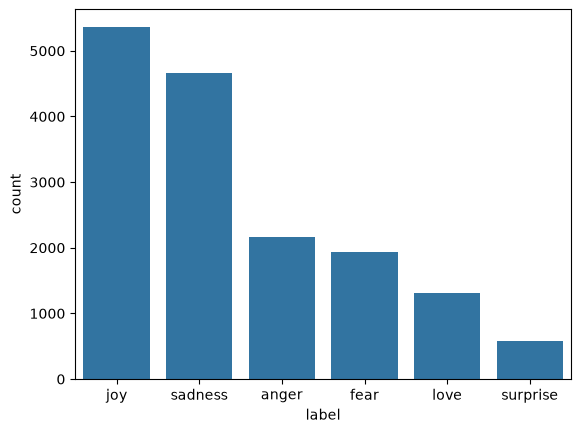

In [8]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [9]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


## 4. Data Preprocessing - Using NLP
Clean the text with the same `preprocess_text` as the server, tokenize, and pad to length 50.
Padding is added at the end (`post`), so every model uses `mask_zero=True` in its Embedding layer:
without the mask, the recurrent layers read up to 49 padding zeros after the sentence and forget it.

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words  = 10000
max_length = 50

for df in (df_train, df_val, df_test):
    df['clean'] = df['text'].apply(preprocess_text)

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['clean'])


def to_padded(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=max_length, padding='post', truncating='post')


padded_train_sequence = to_padded(df_train['clean'])
padded_val_sequence   = to_padded(df_val['clean'])
padded_test_sequence  = to_padded(df_test['clean'])

train_labels = np.array(train_label)
val_labels   = np.array(val_label)
test_labels  = np.array(test_label)

num_classes = len(np.unique(train_labels))

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 50


## 5. Shared Training Utilities
Compute balanced class weights to handle dataset skew and setup early stopping.

In [11]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

## 6. Phase 1 — Plain Foundational Models
Train plain (non-bidirectional) Simple RNN, Standard LSTM, and Standard GRU models.

### 6.1 Model 1 — Simple RNN
Plain unrolled Recurrent Neural Network.

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, mask_zero=True),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [14]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20


  1/500 ━━━━━━━━━━━━━━━━━━━━ 13:11 2s/step - accuracy: 0.1562 - loss: 1.5864

  3/500 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.1771 - loss: 1.6355

  6/500 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.1927 - loss: 1.8063

  9/500 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.1736 - loss: 1.7494

 12/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.1979 - loss: 1.7325

... (2,167 outputs left out)

54/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8125 - loss: 0.6789

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8100 - loss: 0.6827

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8100 - loss: 0.6827


RNN Loss: 0.6826523542404175
RNN Accuracy: 0.8100000023841858


### 6.2 Model 2 — Standard LSTM
Plain stacked Long Short-Term Memory network.

In [15]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, mask_zero=True),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20


  1/500 ━━━━━━━━━━━━━━━━━━━━ 16:26 2s/step - accuracy: 0.3125 - loss: 1.6106

  2/500 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - accuracy: 0.2344 - loss: 1.6791

  4/500 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.1719 - loss: 1.7613

  6/500 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.1615 - loss: 1.7066

  8/500 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.1719 - loss: 1.6680

... (1,529 outputs left out)

58/63 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9009 - loss: 0.3067

62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9002 - loss: 0.3144

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9005 - loss: 0.3132


LSTM Loss: 0.3132047653198242
LSTM Accuracy: 0.9004999995231628


### 6.3 Model 3 — Standard GRU
Plain stacked Gated Recurrent Unit network.

In [16]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, mask_zero=True),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20


  1/500 ━━━━━━━━━━━━━━━━━━━━ 17:47 2s/step - accuracy: 0.1562 - loss: 1.6130

  3/500 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.2083 - loss: 1.6299

  5/500 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.2188 - loss: 1.7206

  7/500 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.2188 - loss: 1.7140

  9/500 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.2083 - loss: 1.6535

... (1,385 outputs left out)

58/63 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9095 - loss: 0.2750

61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9109 - loss: 0.2714

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9105 - loss: 0.2702


GRU Loss: 0.2702367305755615
GRU Accuracy: 0.9104999899864197


### 6.4 Phase 1 Ranking & Selection
Rank foundational models by **validation** accuracy to pick the best base cell for Phase 2 (test accuracy is shown for reference only).

In [17]:
val_acc = {name: m.evaluate(padded_val_sequence, val_labels, verbose=0)[1]
           for name, m in (('RNN', rnn_model), ('LSTM', lstm_model), ('GRU', gru_model))}
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Validation Accuracy': [val_acc['RNN'], val_acc['LSTM'], val_acc['GRU']],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Validation Accuracy', ascending=False)
result_df

,Model,Validation Accuracy,Test Loss,Test Accuracy
2,GRU,0.9210,0.270237,0.9105
1,LSTM,0.9085,0.313205,0.9005
0,RNN,0.8370,0.682652,0.8100


## 7. Phase 2 — Advanced Bidirectional GRU
Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization.

### 7.1 Model 4 — Advanced Stacked Bidirectional GRU

In [18]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300, mask_zero=True),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

#### Train & Evaluate Advanced Bidirectional GRU

In [19]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20


  1/500 ━━━━━━━━━━━━━━━━━━━━ 31:59 4s/step - accuracy: 0.1875 - loss: 1.6078

  2/500 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - accuracy: 0.2344 - loss: 1.6827

  3/500 ━━━━━━━━━━━━━━━━━━━━ 38s 77ms/step - accuracy: 0.1771 - loss: 1.6281

  4/500 ━━━━━━━━━━━━━━━━━━━━ 37s 77ms/step - accuracy: 0.2031 - loss: 1.7647

  5/500 ━━━━━━━━━━━━━━━━━━━━ 38s 77ms/step - accuracy: 0.1937 - loss: 1.7230

... (2,500 outputs left out)

498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9763 - loss: 0.0641

499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9763 - loss: 0.0642

500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9764 - loss: 0.0641

500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 78ms/step - accuracy: 0.9764 - loss: 0.0641 - val_accuracy: 0.9285 - val_loss: 0.2697


In [20]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

 1/63 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9688 - loss: 0.0621

 4/63 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9219 - loss: 0.2311

 7/63 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9375 - loss: 0.1787

10/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9219 - loss: 0.2403

13/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9231 - loss: 0.2288

16/63 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9121 - loss: 0.2747

... (13 outputs left out)

57/63 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9156 - loss: 0.2431

60/63 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9167 - loss: 0.2387

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9170 - loss: 0.2385


BiGRU Loss: 0.23851509392261505
BiGRU Accuracy: 0.9169999957084656


## 8. Overall Evaluation & Bias Analysis
Consolidate test metrics, plot raw & normalized confusion matrices, and analyze bias.

### 8.1 Final Model Confusion Matrices (Raw Counts & Normalized %)

In [21]:
from sklearn.metrics import classification_report

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence, verbose=0), axis=1)
print(classification_report(test_labels, BiGRU_predictions, target_names=label_names, digits=3))

              precision    recall  f1-score   support

     sadness      0.975     0.940     0.957       581
         joy      0.962     0.912     0.936       695
        love      0.763     0.912     0.831       159
       anger      0.915     0.945     0.930       275
        fear      0.934     0.821     0.874       224
    surprise      0.591     0.985     0.739        66

    accuracy                          0.917      2000
   macro avg      0.857     0.919     0.878      2000
weighted avg      0.928     0.917     0.920      2000



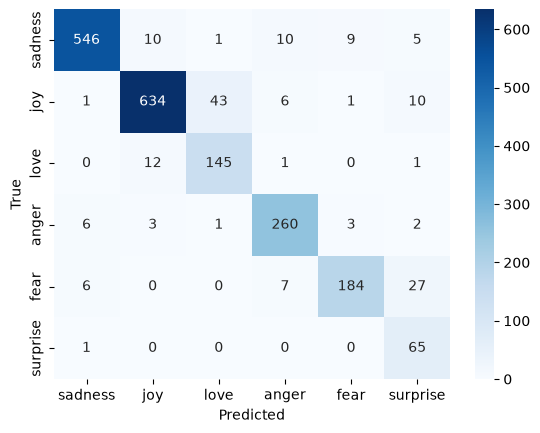

In [22]:
from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(test_labels, BiGRU_predictions), annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

## 9. Final Predictions
Test the winning model on unseen sample sentences.

In [23]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!",
    "I love you so much",
]

sample_padded_sequences = to_padded([preprocess_text(t) for t in sample_texts])
sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences, verbose=0), axis=1)

for text, pred in zip(sample_texts, sample_predictions):
    print(f'Text: {text}\nPredicted Emotion: {label_names[pred]}')

Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise
Text: I love you so much
Predicted Emotion: love


## 10. Save Model & Tokenizer
Export trained model and tokenizer artifacts for API deployment.

In [24]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)